# Importing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Create a sample student dataset
df = pd.DataFrame({
    "Student": range(1, 21),
    "Study_Hours": [
        1, 2, 3, 4, 2, 5, 6, 3, 7, 4,
        8, 5, 6, 9, 2, 7, 8, 3, 10, 6
    ],
    "Attendance": [
        60, 65, 70, 75, 68, 80, 85, 72, 90, 78,
        92, 82, 88, 95, 62, 89, 94, 73, 98, 86
    ],
    "Marks": [
        45, 50, 55, 65, 52, 70, 78, 60, 85, 68,
        90, 74, 82, 95, 48, 84, 92, 58, 98, 80
    ]
})

In [3]:
df.head()

,Student,Study_Hours,Attendance,Marks
0,1,1,60,45
1,2,2,65,50
2,3,3,70,55
3,4,4,75,65
4,5,2,68,52


# Descriptive statistics

In [5]:
print(df.describe())

        Student  Study_Hours  Attendance      Marks
count  20.00000    20.000000   20.000000  20.000000
mean   10.50000     5.050000   80.100000  71.450000
std     5.91608     2.584875   11.548069  16.744127
min     1.00000     1.000000   60.000000  45.000000
25%     5.75000     3.000000   71.500000  57.250000
50%    10.50000     5.000000   81.000000  72.000000
75%    15.25000     7.000000   89.250000  84.250000
max    20.00000    10.000000   98.000000  98.000000


In [6]:
print("\nMedian marks:", df["Marks"].median())


Median marks: 72.0


In [7]:
print("Average marks:", df["Marks"].mean())

Average marks: 71.45


In [8]:
print("Standard deviation:", df["Marks"].std())

Standard deviation: 16.744127014379824


# Visualize distributions

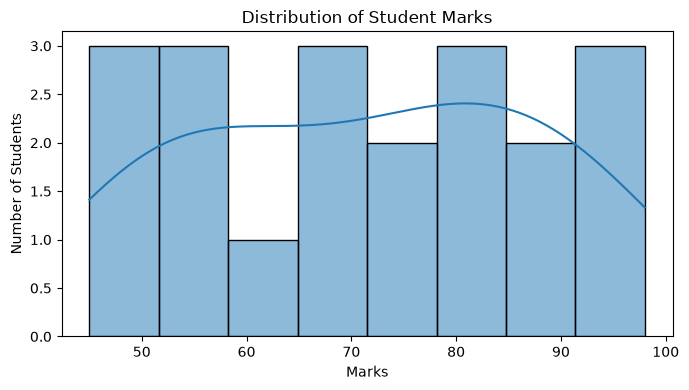

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Marks"], bins=8, kde=True)
plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# Correlation vs. causation

             Study_Hours  Attendance     Marks
Study_Hours     1.000000    0.981917  0.989301
Attendance      0.981917    1.000000  0.995976
Marks           0.989301    0.995976  1.000000


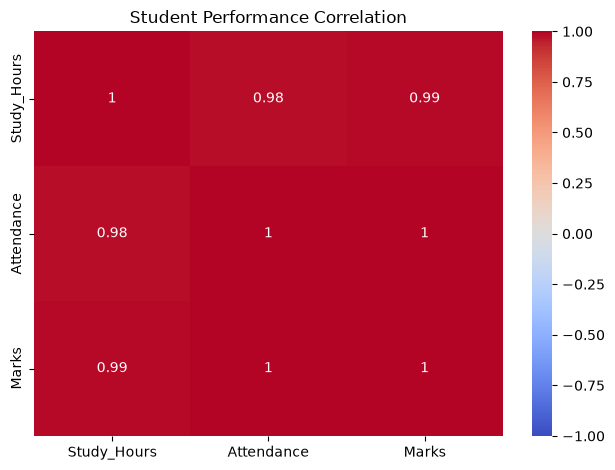

In [10]:
correlation = df[
    ["Study_Hours", "Attendance", "Marks"]
].corr()

print(correlation)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Student Performance Correlation")
plt.tight_layout()
plt.show()

# Compare sampling results

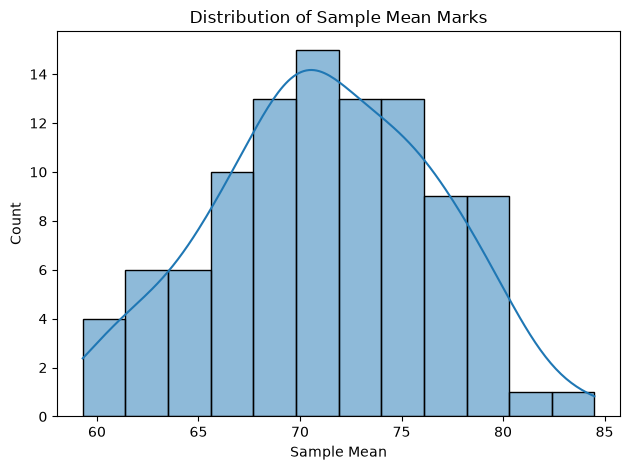

Mean of sample means: 71.192


In [11]:
sample_means = [
    df["Marks"].sample(
        n=10, replace=True, random_state=i
    ).mean()
    for i in range(100)
]

sns.histplot(sample_means, bins=12, kde=True)
plt.title("Distribution of Sample Mean Marks")
plt.xlabel("Sample Mean")
plt.tight_layout()
plt.show()

print("Mean of sample means:", np.mean(sample_means))

# Data cleaning

In [12]:
# Create a separate copy for cleaning practice
clean_df = df.copy()

In [15]:
# Introduce a missing value and duplicate row
clean_df.loc[0, "Marks"] = np.nan
clean_df = pd.concat(
    [clean_df, clean_df.iloc[[1]]],
    ignore_index=True
)

print("Missing values:\n", clean_df.isnull().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

Missing values:
 Student        0
Study_Hours    0
Attendance     0
Marks          1
dtype: int64
Duplicate rows: 1


In [16]:
clean_df = clean_df.drop_duplicates().copy()
clean_df["Marks"] = clean_df["Marks"].fillna(
    clean_df["Marks"].median()
)

print("After cleaning:\n", clean_df.isnull().sum())

After cleaning:
 Student        0
Study_Hours    0
Attendance     0
Marks          0
dtype: int64
